# Pipeline de dados — indicadores de risco de atraso (Olist)
## Projeto Aplicado I — *Olist: o Peso da Espera* — Etapa 4

**Aluno:** Felipe Passador Leite — RA 10401969

Na Etapa 3, a análise exploratória mostrou que (i) apenas uma minoria dos pedidos chega atrasada, (ii) esses pedidos
concentram as notas baixas e (iii) a taxa de atraso varia bastante entre os estados. A **proposta analítica** do
projeto é um **painel de monitoramento do risco de atraso**, por estado (UF) e por categoria de produto.

Este notebook implementa o **pipeline de dados** que alimenta esse painel, do arquivo bruto até a tabela de indicadores:

| Etapa | O que faz | Seção |
|---|---|---|
| 1. Extração e carga | lê os CSVs do dataset (pasta `dados/`) | 2 |
| 2. Tratamento | converte datas, calcula atraso e tempo de entrega, filtra pedidos entregues | 3 |
| 3. Integração | junta pedidos, avaliações, clientes, itens e categorias (uma linha por pedido) | 4 |
| 4. Indicadores | calcula taxa de atraso, tempo, nota média e notas baixas por UF e por categoria | 5 |
| 5. Classificação de risco | aplica uma regra simples e transparente (alto / médio / baixo) | 6 |
| 6. Saída | grava as tabelas em CSV (a "base do painel") e gera os gráficos | 7 e 8 |

**Como executar:** abra este notebook a partir da pasta `notebooks/` e use *Kernel → Restart & Run All*.
Os CSVs são lidos de `../dados/`.

## 1. Configuração

Bibliotecas e parâmetros do pipeline. Os parâmetros ficam todos aqui, no início, para que possam ser alterados em um só lugar.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# Paleta sóbria (tons de cinza) com vermelho reservado para o que é "problema" (risco alto)
COR_PRINCIPAL = "#4d4d4d"
COR_SECUNDARIA = "#a6a6a6"
COR_DESTAQUE = "#b22222"

# ---- Parâmetros do pipeline ----
CAMINHO_DADOS = "../dados/"
MIN_PEDIDOS_UF = 500          # estados com menos pedidos entregues não entram no ranking
MIN_PEDIDOS_CATEGORIA = 300   # categorias com menos pedidos entregues não entram no ranking
LIMITE_NOTA_BAIXA = 2         # nota 1 ou 2 = cliente insatisfeito
FATOR_RISCO_ALTO = 1.5        # risco ALTO se taxa de atraso >= 1,5 x a taxa geral

## 2. Extração e carga

Lemos apenas as tabelas necessárias para o painel (a tabela `geolocation` e a de pagamentos não são usadas aqui).
Cada função `pd.read_csv` transforma um arquivo CSV em um *DataFrame* (uma tabela em memória).

In [2]:
orders = pd.read_csv(CAMINHO_DADOS + "olist_orders_dataset.csv")
reviews = pd.read_csv(CAMINHO_DADOS + "olist_order_reviews_dataset.csv")
customers = pd.read_csv(CAMINHO_DADOS + "olist_customers_dataset.csv")
items = pd.read_csv(CAMINHO_DADOS + "olist_order_items_dataset.csv")
products = pd.read_csv(CAMINHO_DADOS + "olist_products_dataset.csv")
traducao = pd.read_csv(CAMINHO_DADOS + "product_category_name_translation.csv")

for nome, df in {"orders": orders, "reviews": reviews, "customers": customers,
                 "items": items, "products": products, "traducao": traducao}.items():
    print(f"{nome:10s}: {df.shape[0]:>7,} linhas x {df.shape[1]} colunas")

orders    :  99,441 linhas x 8 colunas
reviews   :  99,224 linhas x 7 colunas
customers :  99,441 linhas x 5 colunas
items     : 112,650 linhas x 7 colunas
products  :  32,951 linhas x 9 colunas
traducao  :      71 linhas x 2 colunas


## 3. Tratamento

Três decisões de tratamento, todas registradas aqui para que o resultado possa ser reproduzido:

1. **Datas:** as colunas de data vêm como texto e são convertidas para `datetime`.
2. **Pedidos considerados:** apenas pedidos com data de entrega ao cliente registrada. Pedidos cancelados, indisponíveis ou ainda em trânsito não têm como ter o atraso medido; eles são **excluídos**, e não preenchidos artificialmente.
3. **Variáveis derivadas:** `atraso_dias` (data real − data estimada; positivo = atrasado), `tempo_entrega_dias` (compra → entrega) e `atrasado` (verdadeiro quando `atraso_dias > 0`).

In [3]:
colunas_data = ["order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date"]
for c in colunas_data:
    orders[c] = pd.to_datetime(orders[c])

total_pedidos = len(orders)
pedidos = orders.dropna(subset=["order_delivered_customer_date"]).copy()
print(f"Pedidos no dataset: {total_pedidos:,}")
print(f"Pedidos com data de entrega registrada (analisados): {len(pedidos):,}")
print(f"Pedidos excluídos por não terem data de entrega: {total_pedidos - len(pedidos):,}")

pedidos["atraso_dias"] = (pedidos["order_delivered_customer_date"] - pedidos["order_estimated_delivery_date"]).dt.days
pedidos["tempo_entrega_dias"] = (pedidos["order_delivered_customer_date"] - pedidos["order_purchase_timestamp"]).dt.days
pedidos["atrasado"] = pedidos["atraso_dias"] > 0

pedidos[["order_id", "atraso_dias", "tempo_entrega_dias", "atrasado"]].head()

Pedidos no dataset: 99,441
Pedidos com data de entrega registrada (analisados): 96,476
Pedidos excluídos por não terem data de entrega: 2,965


,order_id,atraso_dias,tempo_entrega_dias,atrasado
0,e481f51cbdc54678b7cc49136f2d6af7,-8,8,False
1,53cdb2fc8bc7dce0b6741e2150273451,-6,13,False
2,47770eb9100c2d0c44946d9cf07ec65d,-18,9,False
3,949d5b44dbf5de918fe9c16f97b45f8a,-13,13,False
4,ad21c59c0840e6cb83a9ceb5573f8159,-10,2,False


## 4. Integração (uma linha por pedido)

Para calcular indicadores por pedido, precisamos garantir que cada pedido apareça **uma única vez** na tabela final.
Duas tabelas exigem cuidado, porque um mesmo pedido pode ter mais de uma linha:

- **Avaliações:** alguns pedidos têm mais de uma avaliação. Mantemos a **mais recente** (`review_answer_timestamp`).
- **Itens:** um pedido pode ter itens de categorias diferentes. Adotamos a **categoria do primeiro item** (`order_item_id == 1`). É uma simplificação, registrada como limitação do estudo.

Depois, a tabela de tradução converte o nome da categoria para o inglês. Categorias sem tradução mantêm o nome original em português.

In [4]:
# --- avaliações: uma por pedido (a mais recente) ---
print(f"Avaliações: {len(reviews):,} | pedidos distintos avaliados: {reviews['order_id'].nunique():,}")
reviews["review_answer_timestamp"] = pd.to_datetime(reviews["review_answer_timestamp"])
reviews_unicas = (reviews.sort_values("review_answer_timestamp")
                         .drop_duplicates(subset="order_id", keep="last")
                         [["order_id", "review_score"]])
print(f"Após manter 1 avaliação por pedido: {len(reviews_unicas):,}")

# --- categoria do primeiro item de cada pedido ---
primeiro_item = items[items["order_item_id"] == 1][["order_id", "product_id"]]
primeiro_item = primeiro_item.merge(products[["product_id", "product_category_name"]], on="product_id", how="left")
primeiro_item = primeiro_item.merge(traducao, on="product_category_name", how="left")
primeiro_item["categoria"] = (primeiro_item["product_category_name_english"]
                              .fillna(primeiro_item["product_category_name"])
                              .fillna("sem_categoria"))
primeiro_item = primeiro_item[["order_id", "categoria"]]

# --- junção final (merge): a chave é order_id (ou customer_id, para o estado) ---
base = (pedidos
        .merge(customers[["customer_id", "customer_state"]], on="customer_id", how="left")
        .merge(reviews_unicas, on="order_id", how="inner")      # só pedidos com nota
        .merge(primeiro_item, on="order_id", how="left"))
base["categoria"] = base["categoria"].fillna("sem_categoria")
base["nota_baixa"] = base["review_score"] <= LIMITE_NOTA_BAIXA

# --- verificações de qualidade antes de seguir ---
assert base["order_id"].is_unique, "há pedidos duplicados na base final"
print(f"\nBase final: {len(base):,} pedidos (1 linha por pedido)")
print("Valores ausentes por coluna analítica:")
print(base[["customer_state", "review_score", "categoria", "atraso_dias"]].isna().sum().to_string())
base[["order_id", "customer_state", "categoria", "atraso_dias", "atrasado", "review_score"]].head()

Avaliações: 99,224 | pedidos distintos avaliados: 98,673


Após manter 1 avaliação por pedido: 98,673



Base final: 95,830 pedidos (1 linha por pedido)
Valores ausentes por coluna analítica:
customer_state    0
review_score      0
categoria         0
atraso_dias       0


,order_id,customer_state,categoria,atraso_dias,atrasado,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,SP,housewares,-8,False,4
1,53cdb2fc8bc7dce0b6741e2150273451,BA,perfumery,-6,False,4
2,47770eb9100c2d0c44946d9cf07ec65d,GO,auto,-18,False,5
3,949d5b44dbf5de918fe9c16f97b45f8a,RN,pet_shop,-13,False,5
4,ad21c59c0840e6cb83a9ceb5573f8159,SP,stationery,-10,False,5


## 5. Indicadores

Para cada grupo (estado ou categoria), calculamos:

| Indicador | Significado |
|---|---|
| `pedidos` | quantidade de pedidos entregues (com nota) |
| `pedidos_atrasados` | quantos chegaram depois da data estimada |
| `pct_atrasados` | **taxa de atraso** = pedidos atrasados ÷ pedidos |
| `tempo_medio_dias` | tempo médio entre compra e entrega |
| `nota_media` | média de `review_score` |
| `pct_notas_baixas` | % de avaliações com nota 1 ou 2 |
| `pct_do_total_atrasos` | quanto aquele grupo representa de **todos** os atrasos (indica onde está o volume) |

Uma função única calcula esses indicadores para qualquer coluna de agrupamento, evitando repetir o mesmo código.

In [5]:
def calcular_indicadores(df, coluna_grupo, minimo_pedidos):
    """Agrupa df por coluna_grupo e calcula os indicadores de entrega e satisfação."""
    ind = df.groupby(coluna_grupo).agg(
        pedidos=("order_id", "count"),
        pedidos_atrasados=("atrasado", "sum"),
        pct_atrasados=("atrasado", "mean"),
        tempo_medio_dias=("tempo_entrega_dias", "mean"),
        nota_media=("review_score", "mean"),
        pct_notas_baixas=("nota_baixa", "mean"),
    )
    ind["pct_atrasados"] *= 100
    ind["pct_notas_baixas"] *= 100
    ind["pct_do_total_atrasos"] = ind["pedidos_atrasados"] / df["atrasado"].sum() * 100
    ind = ind[ind["pedidos"] >= minimo_pedidos]          # evita conclusões com poucos pedidos
    return ind.sort_values("pct_atrasados", ascending=False).round(2)


taxa_geral = base["atrasado"].mean() * 100
print(f"Taxa geral de atraso: {taxa_geral:.2f}%  |  nota média geral: {base['review_score'].mean():.2f}")

ind_uf = calcular_indicadores(base, "customer_state", MIN_PEDIDOS_UF)
ind_cat = calcular_indicadores(base, "categoria", MIN_PEDIDOS_CATEGORIA)
print(f"\nEstados no ranking: {len(ind_uf)} | categorias no ranking: {len(ind_cat)}")
ind_uf

Taxa geral de atraso: 6.66%  |  nota média geral: 4.16

Estados no ranking: 17 | categorias no ranking: 32


,pedidos,pedidos_atrasados,pct_atrasados,tempo_medio_dias,nota_media,pct_notas_baixas,pct_do_total_atrasos
customer_state,,,,,,,
MA,712,122,17.13,20.99,3.83,19.94,1.91
CE,1273,174,13.67,20.76,3.94,17.12,2.73
RJ,12214,1456,11.92,14.78,3.96,18.35,22.81
BA,3229,384,11.89,18.78,3.93,17.00,6.02
PA,933,100,10.72,23.18,3.91,17.90,1.57
ES,1969,205,10.41,15.15,4.08,13.81,3.21
PB,512,52,10.16,19.77,4.08,14.84,0.81
MS,699,68,9.73,15.20,4.16,13.30,1.07
PE,1579,149,9.44,17.89,4.08,14.82,2.33


In [6]:
ind_cat

,pedidos,pedidos_atrasados,pct_atrasados,tempo_medio_dias,nota_media,pct_notas_baixas,pct_do_total_atrasos
categoria,,,,,,,
audio,341,40,11.73,13.03,3.85,21.41,0.63
home_confort,368,35,9.51,13.09,3.91,17.93,0.55
baby,2741,220,8.03,12.18,4.12,13.75,3.45
office_furniture,1236,99,8.01,20.17,3.65,21.84,1.55
musical_instruments,601,46,7.65,12.64,4.25,11.31,0.72
electronics,2488,190,7.64,12.45,4.13,13.06,2.98
health_beauty,8563,634,7.40,11.61,4.23,11.28,9.93
bed_bath_table,9072,668,7.36,12.51,4.01,15.73,10.47
watches_gifts,5430,395,7.27,12.30,4.13,13.54,6.19


## 6. Classificação de risco

Para que o painel aponte rapidamente onde agir, aplicamos uma **regra simples e transparente**, que pode ser explicada a qualquer pessoa da área de negócio:

- **ALTO:** taxa de atraso do grupo ≥ 1,5 × a taxa geral;
- **MÉDIO:** taxa de atraso acima da taxa geral, mas abaixo do limite de risco alto;
- **BAIXO:** taxa de atraso igual ou abaixo da taxa geral.

Escolhemos uma regra e não um modelo de aprendizado de máquina porque, nesta etapa, o objetivo é **monitorar e priorizar**, e a regra pode ser conferida a olho nu. Os limites ficam nos parâmetros do início do notebook.

In [7]:
def classificar_risco(pct_atrasados):
    if pct_atrasados >= FATOR_RISCO_ALTO * taxa_geral:
        return "ALTO"
    if pct_atrasados > taxa_geral:
        return "MÉDIO"
    return "BAIXO"

for tabela in (ind_uf, ind_cat):
    tabela["risco"] = tabela["pct_atrasados"].apply(classificar_risco)

print("Estados por nível de risco:")
print(ind_uf["risco"].value_counts().to_string())
print("\nCategorias por nível de risco:")
print(ind_cat["risco"].value_counts().to_string())

# Taxa x volume: o estado com maior TAXA nem sempre é o que concentra mais atrasos
print("\nEstados com risco ALTO, ordenados pelo volume de atrasos:")
ind_uf[ind_uf["risco"] == "ALTO"].sort_values("pedidos_atrasados", ascending=False)[
    ["pedidos", "pedidos_atrasados", "pct_atrasados", "pct_do_total_atrasos", "nota_media"]]

Estados por nível de risco:
risco
ALTO     7
BAIXO    7
MÉDIO    3

Categorias por nível de risco:
risco
BAIXO    16
MÉDIO    15
ALTO      1

Estados com risco ALTO, ordenados pelo volume de atrasos:


,pedidos,pedidos_atrasados,pct_atrasados,pct_do_total_atrasos,nota_media
customer_state,,,,,
RJ,12214,1456,11.92,22.81,3.96
BA,3229,384,11.89,6.02,3.93
ES,1969,205,10.41,3.21,4.08
CE,1273,174,13.67,2.73,3.94
MA,712,122,17.13,1.91,3.83
PA,933,100,10.72,1.57,3.91
PB,512,52,10.16,0.81,4.08


## 7. Saída do pipeline: a base do painel

As tabelas de indicadores são gravadas em CSV. Esses arquivos são a **base de dados do painel proposto**: qualquer ferramenta de visualização (Power BI, Looker Studio, Excel) consegue lê-los diretamente.

In [8]:
ind_uf.to_csv("indicadores_por_estado.csv", index_label="estado")
ind_cat.to_csv("indicadores_por_categoria.csv", index_label="categoria")
print("Arquivos gravados: indicadores_por_estado.csv e indicadores_por_categoria.csv")

Arquivos gravados: indicadores_por_estado.csv e indicadores_por_categoria.csv


## 8. Visualizações do painel

Três gráficos resumem o que o painel mostraria: o ranking por estado, a relação entre taxa de atraso e satisfação, e o ranking por categoria.

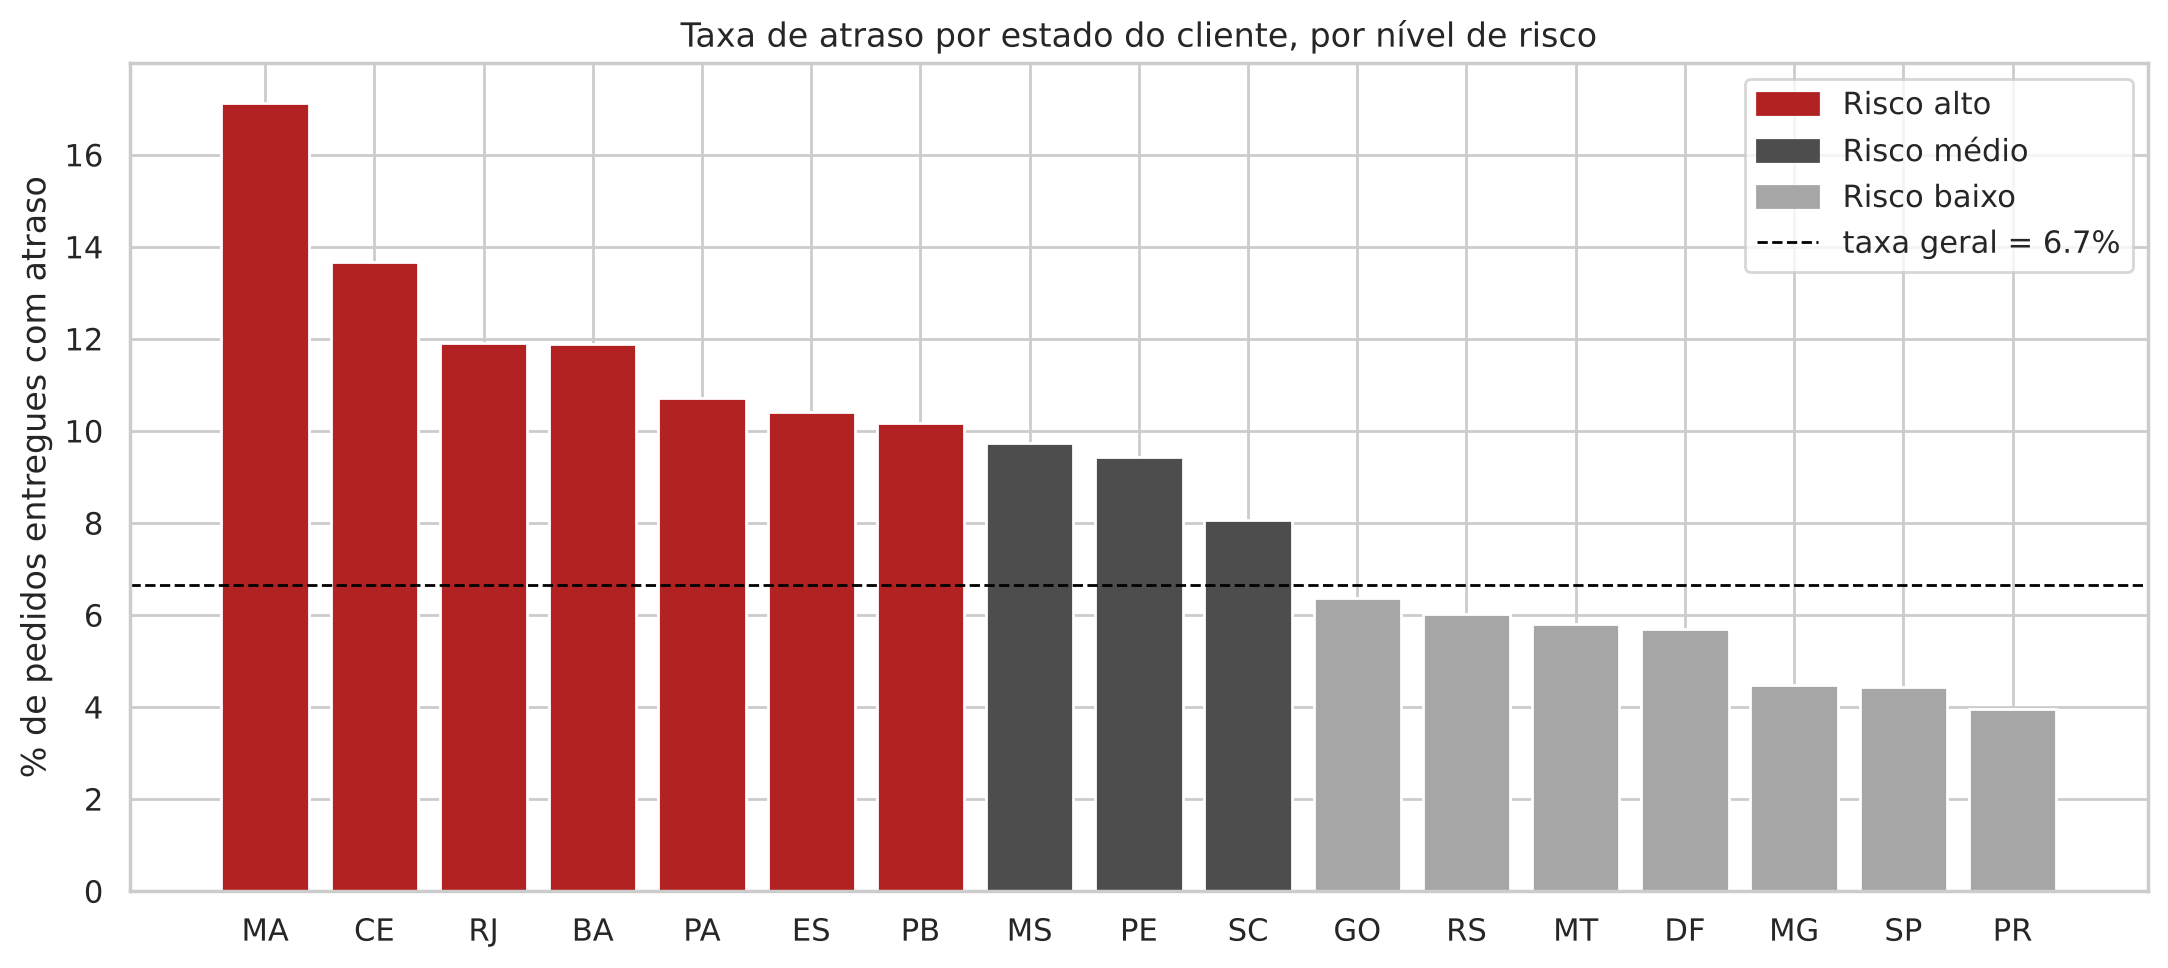

In [9]:
cores_risco = {"ALTO": COR_DESTAQUE, "MÉDIO": COR_PRINCIPAL, "BAIXO": COR_SECUNDARIA}

# Gráfico 1: taxa de atraso por estado, colorida pelo nível de risco
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(ind_uf.index, ind_uf["pct_atrasados"], color=[cores_risco[r] for r in ind_uf["risco"]])
ax.axhline(taxa_geral, color="black", linestyle="--", linewidth=1, label=f"taxa geral = {taxa_geral:.1f}%")
ax.set_title("Taxa de atraso por estado do cliente, por nível de risco")
ax.set_ylabel("% de pedidos entregues com atraso")
handles = [plt.Rectangle((0, 0), 1, 1, color=cores_risco[r]) for r in ("ALTO", "MÉDIO", "BAIXO")]
ax.legend(handles + [ax.lines[0]], ["Risco alto", "Risco médio", "Risco baixo", ax.lines[0].get_label()])
plt.tight_layout()
plt.savefig("painel_risco_por_estado.png", dpi=120)
plt.show()

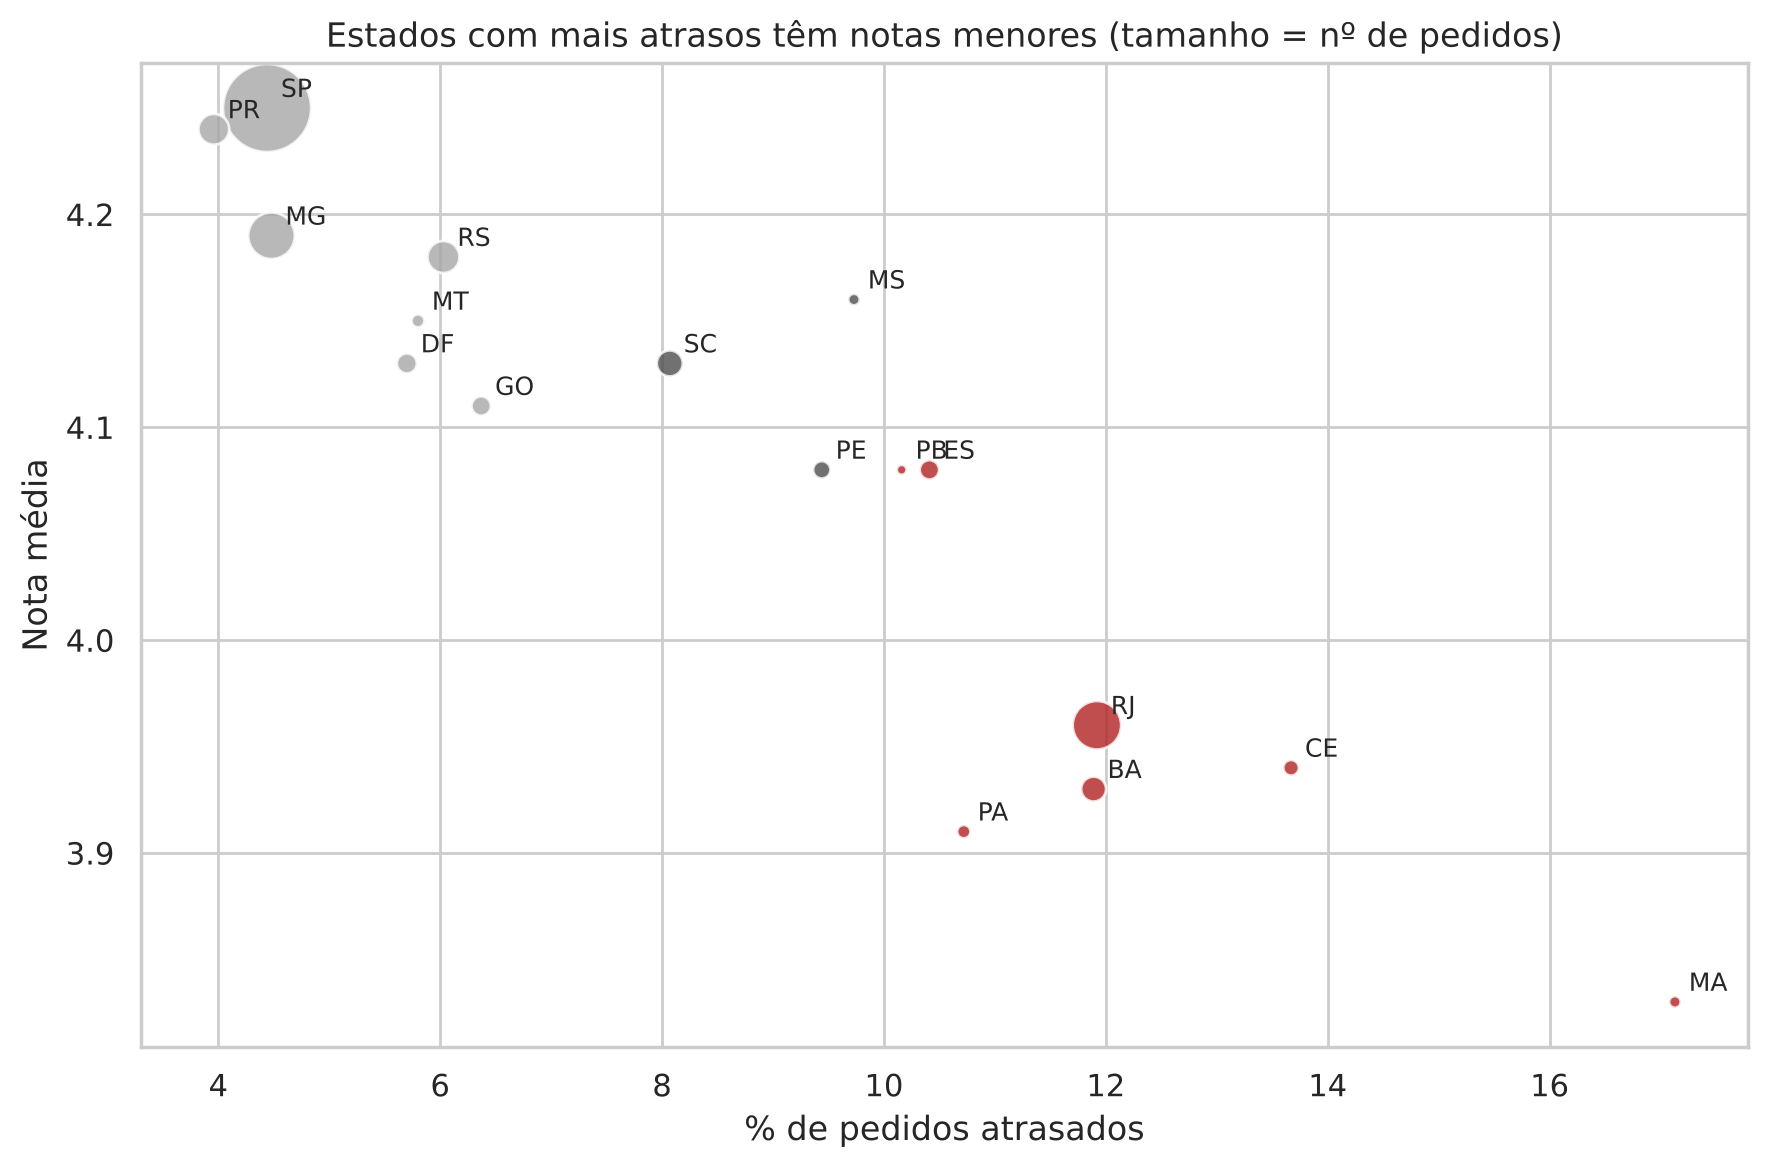

Correlação entre taxa de atraso e nota média (entre os estados): -0.914


In [10]:
# Gráfico 2: taxa de atraso x nota média por estado (o tamanho do ponto = volume de pedidos)
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(ind_uf["pct_atrasados"], ind_uf["nota_media"], s=ind_uf["pedidos"] / 40,
           c=[cores_risco[r] for r in ind_uf["risco"]], alpha=0.8, edgecolor="white")
for uf, linha in ind_uf.iterrows():
    ax.annotate(uf, (linha["pct_atrasados"], linha["nota_media"]), xytext=(5, 4), textcoords="offset points", fontsize=9)
ax.set_title("Estados com mais atrasos têm notas menores (tamanho = nº de pedidos)")
ax.set_xlabel("% de pedidos atrasados")
ax.set_ylabel("Nota média")
plt.tight_layout()
plt.savefig("painel_atraso_vs_nota_por_estado.png", dpi=120)
plt.show()

print("Correlação entre taxa de atraso e nota média (entre os estados):",
      round(ind_uf["pct_atrasados"].corr(ind_uf["nota_media"]), 3))

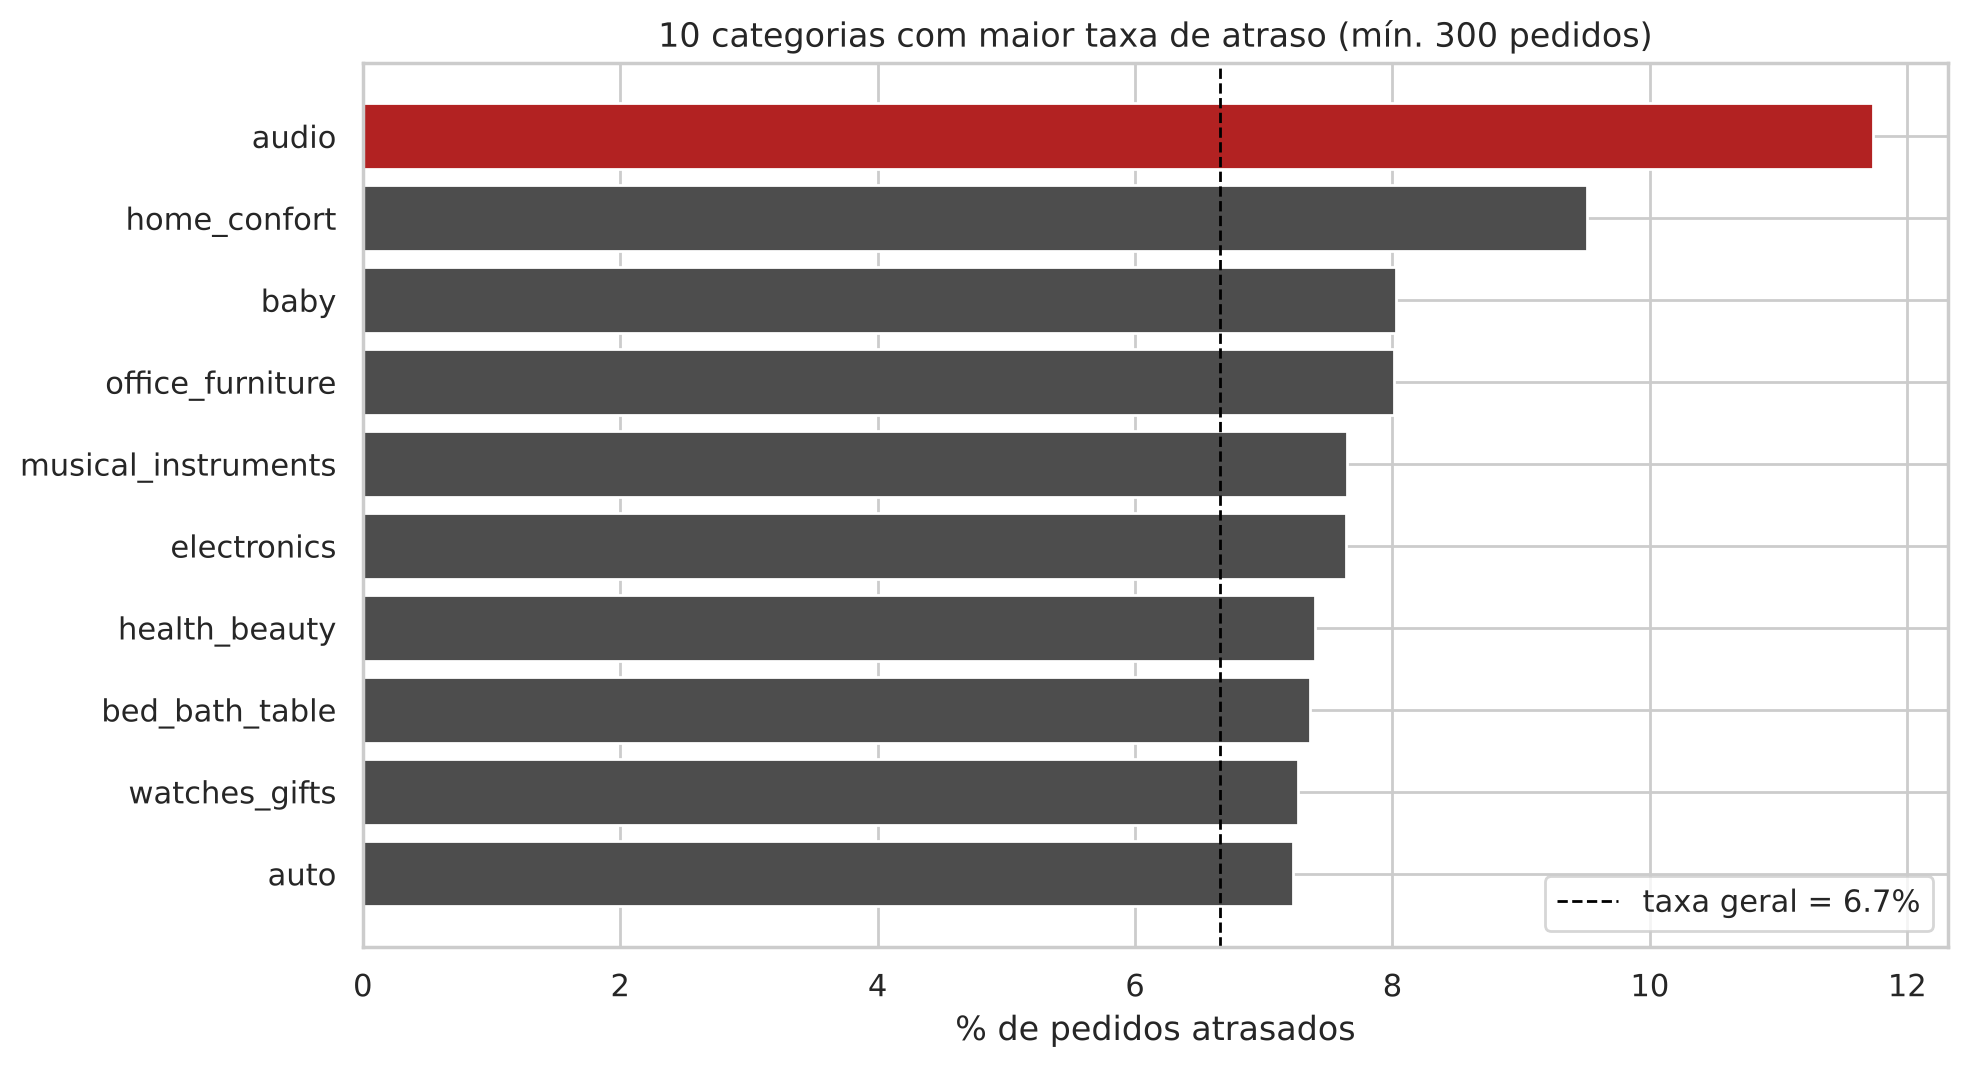

In [11]:
# Gráfico 3: as 10 categorias com maior taxa de atraso
top_cat = ind_cat.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(top_cat.index, top_cat["pct_atrasados"], color=[cores_risco[r] for r in top_cat["risco"]])
ax.axvline(taxa_geral, color="black", linestyle="--", linewidth=1, label=f"taxa geral = {taxa_geral:.1f}%")
ax.set_title(f"10 categorias com maior taxa de atraso (mín. {MIN_PEDIDOS_CATEGORIA} pedidos)")
ax.set_xlabel("% de pedidos atrasados")
ax.legend()
plt.tight_layout()
plt.savefig("painel_risco_por_categoria.png", dpi=120)
plt.show()

## 9. Validação do pipeline

Um pipeline só é confiável se o resultado puder ser **conferido**. Aqui comparamos os números da base final com os valores já obtidos na análise exploratória (notebook 01) e verificamos que os totais por grupo fecham.

In [12]:
# 1) A soma dos pedidos de todos os estados (antes do corte de volume mínimo) deve ser igual à base
soma_uf = base.groupby("customer_state")["order_id"].count().sum()
assert soma_uf == len(base)
print(f"OK — soma dos pedidos por estado = total da base = {soma_uf:,}")

# 2) Pedidos atrasados: total da base x soma dos grupos
assert base.groupby("customer_state")["atrasado"].sum().sum() == base["atrasado"].sum()
print(f"OK — total de pedidos atrasados = {int(base['atrasado'].sum()):,}")

# 3) Comparação com a análise exploratória (notebook 01), que usava todas as avaliações (inclusive repetidas)
orders_reviews = orders.merge(reviews[["order_id", "review_score"]], on="order_id", how="inner").dropna(subset=["order_delivered_customer_date"])
print(f"\nNotebook 01 (todas as avaliações): {len(orders_reviews):,} registros")
print(f"Pipeline (1 avaliação por pedido) : {len(base):,} pedidos")
print(f"Diferença: {len(orders_reviews) - len(base):,} registros — são avaliações repetidas do mesmo pedido.")

# 4) Os indicadores gerais continuam praticamente iguais?
print(f"\nTaxa de atraso — pipeline: {taxa_geral:.2f}%")
print(f"Notas 1 ou 2 entre atrasados — pipeline: {base[base['atrasado']]['nota_baixa'].mean()*100:.1f}%")
print(f"Notas 1 ou 2 entre os no prazo — pipeline: {base[~base['atrasado']]['nota_baixa'].mean()*100:.1f}%")

OK — soma dos pedidos por estado = total da base = 95,830
OK — total de pedidos atrasados = 6,382

Notebook 01 (todas as avaliações): 96,359 registros
Pipeline (1 avaliação por pedido) : 95,830 pedidos
Diferença: 529 registros — são avaliações repetidas do mesmo pedido.

Taxa de atraso — pipeline: 6.66%
Notas 1 ou 2 entre atrasados — pipeline: 62.4%
Notas 1 ou 2 entre os no prazo — pipeline: 9.3%


## 10. Conclusão e limitações

**O que o pipeline entrega:** duas tabelas de indicadores (por estado e por categoria), prontas para alimentar um painel, com uma classificação de risco explicável.

**Limitações (a registrar no documento):**
- O dataset cobre **2016 a 2018**; os níveis de risco refletem esse período e não devem ser tomados como retrato atual da operação da Olist.
- A categoria do pedido é a do **primeiro item**; pedidos com itens de categorias diferentes são simplificados.
- Pedidos sem data de entrega (cerca de 3%) ficam de fora, pois o atraso não pode ser medido.
- A análise mostra **associação** entre atraso e nota, e não prova que o atraso é a causa única da insatisfação.
- A regra de risco usa limites escolhidos para este estudo (parâmetros do início do notebook); outros limites mudariam a classificação.